In [ ]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table as table, join
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib as mpl
import os
from scipy.stats
import glob
%matplotlib inline
from astropy.nddata import CCDData
import astropy.units as u
import urllib.request

In [ ]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='grey_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

In [ ]:
# Getting image files
base_url = "https://portal.nersc.gov/cfs/cosmo/data/legacysurvey/dr11/south/coadd"

files = {
    "M67_g": f"{base_url}/132/1329p117/legacysurvey-1329p117-image-g.fits.fz",
    "M67_r": f"{base_url}/132/1329p117/legacysurvey-1329p117-image-r.fits.fz",

    "M3_tile1_g": f"{base_url}/205/2056p285/legacysurvey-2056p285-image-g.fits.fz",
    "M3_tile1_r": f"{base_url}/205/2056p285/legacysurvey-2056p285-image-r.fits.fz",

    "M3_tile2_g": f"{base_url}/205/2056p282/legacysurvey-2056p282-image-g.fits.fz",
    "M3_tile2_r": f"{base_url}/205/2056p282/legacysurvey-2056p282-image-r.fits.fz",

    "M3_tile3_g": f"{base_url}/205/2054p285/legacysurvey-2054p285-image-g.fits.fz",
    "M3_tile3_r": f"{base_url}/205/2054p285/legacysurvey-2054p285-image-r.fits.fz",
}

In [ ]:
# Downloading images
os.makedirs("fits_data", exist_ok=True)

local_files = {}

for name, url in files.items():
    path = f"fits_data/{name}.fits.fz"

    if not os.path.exists(path):
        print(f"Downloading {name}...")
        urllib.request.urlretrieve(url, path)

    local_files[name] = path

print("All files downloaded.")

All files downloaded.


In [ ]:
# Get structure and header information
image_data = {}
image_headers = {}

keywords = [
    "BUNIT", "FILTER", "NAXIS1", "NAXIS2",
    "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2",
    "CD1_1", "CD1_2", "CD2_1", "CD2_2"
]

for name, path in local_files.items():
    with fits.open(path) as hdul:
        print(f"\n{'='*60}")
        print(name)
        hdul.info()

        # Find the first 2D image HDU
        image_hdu = next(
            hdu for hdu in hdul
            if hdu.data is not None and hdu.data.ndim == 2
        )

        image_data[name] = image_hdu.data
        image_headers[name] = image_hdu.header

        print("Image shape:", image_hdu.data.shape)

        for key in keywords:
            print(f"{key}: {image_hdu.header.get(key, 'Not available')}")


M67_g
Filename: fits_data/M67_g.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  IMAGE_g       1 CompImageHDU    133   (3600, 3600)   float32   
Image shape: (3600, 3600)
BUNIT: nanomaggy
FILTER: g DECam SDSS c0001 4720.0 1520.0
NAXIS1: 3600
NAXIS2: 3600
CRVAL1: 132.960339943343
CRVAL2: 11.75
CRPIX1: 1800.5
CRPIX2: 1800.5
CD1_1: -7.27777777777778e-05
CD1_2: 0.0
CD2_1: 0.0
CD2_2: 7.27777777777778e-05

M67_r
Filename: fits_data/M67_r.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  IMAGE_r       1 CompImageHDU    133   (3600, 3600)   float32   
Image shape: (3600, 3600)
BUNIT: nanomaggy
FILTER: r DECam SDSS c0002 6415.0 1480.0
NAXIS1: 3600
NAXIS2: 3600
CRVAL1: 132.960339943343
CRVAL2: 11.75
CRPIX1: 1800.5
CRPIX2: 1800.5
CD1_1: -7.27777777777778e-05
CD1_2: 0.0
CD2_1: 0.0
CD2_2: 7.27777777777778e-05

M3_tile1_g
Filename: fits_data/M3_til

In [ ]:
# Acess Pixel values
for name, data in image_data.items():
    print(f"\n{name}")
    print("Pixel [100, 100]:", data[100, 100])
    print("First 10 pixels of row 100:", data[100, :10])
    print("10 x 10 region:")
    print(data[100:110, 100:110])


M67_g
Pixel [100, 100]: 0.001579594
First 10 pixels of row 100: [ 0.00290016  0.00028701  0.0020246  -0.0031457  -0.00215312  0.00417826
 -0.00100454 -0.00306773  0.00073223  0.00110669]
10 x 10 region:
[[ 1.57959398e-03  6.75880699e-04  1.26744492e-03 -2.41327914e-03
  -5.45280287e-04  3.91360559e-03 -1.08754938e-03 -6.02684973e-04
   4.12906113e-04  1.35291915e-03]
 [ 3.49076837e-03 -5.16604283e-04 -4.02855361e-03 -2.45955540e-03
   4.90700244e-04  2.13824608e-03  2.34120805e-03  5.23064111e-04
   6.78587239e-04 -4.44427179e-03]
 [ 6.26036199e-04  3.83063778e-03 -4.12854645e-03 -3.63840093e-03
   2.43512192e-03  2.33531510e-03  3.82845232e-04 -2.78027053e-03
  -2.36752047e-03 -5.27949911e-03]
 [-3.43681173e-03 -3.85719235e-03  1.40472106e-03 -1.16679585e-05
  -1.76363834e-03  1.06898963e-03 -2.75079953e-03 -3.24890926e-03
  -1.37955241e-03 -3.89812351e-03]
 [ 1.34808524e-03  3.07968556e-04  5.76767884e-03  5.81956096e-03
   3.30594601e-03 -9.22529958e-04  4.78218659e-04  6.60937803e

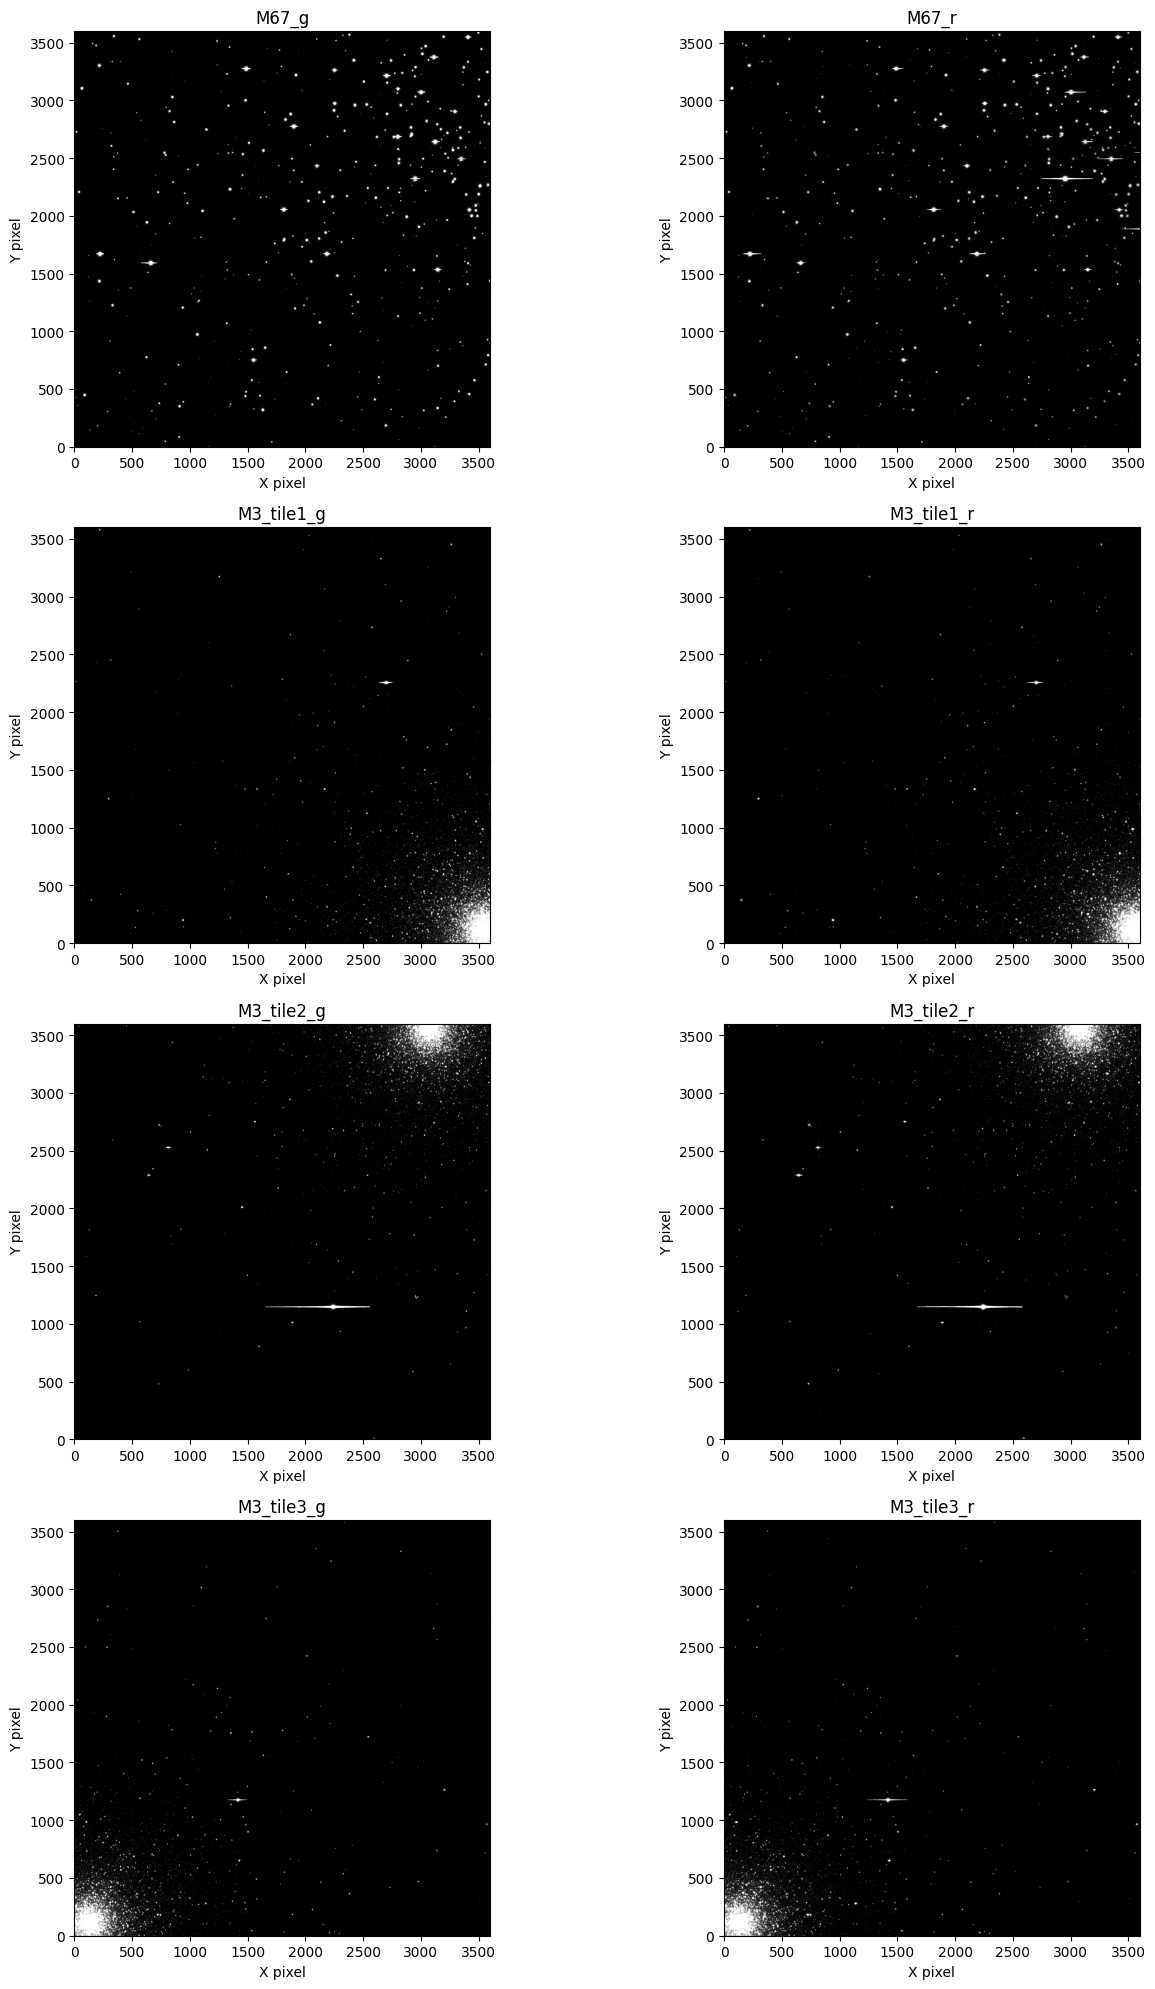

In [ ]:
# Display images
fig, axes = plt.subplots(4, 2, figsize=(14, 20))

for ax, (name, data) in zip(axes.flat, image_data.items()):
    vmin = np.nanpercentile(data, 5)
    vmax = np.nanpercentile(data, 99.5)

    ax.imshow(
        data,
        origin="lower",
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(name)
    ax.set_xlabel("X pixel")
    ax.set_ylabel("Y pixel")

plt.tight_layout()
plt.show()

In [ ]:
# Examine pixel values and units
for name, data in image_data.items():
    header = image_headers[name]

    print(f"\n{name}")
    print("Units:", header.get("BUNIT", "Check header"))
    print("Minimum:", np.nanmin(data))
    print("Maximum:", np.nanmax(data))
    print("Median:", np.nanmedian(data))
    print("Standard deviation:", np.nanstd(data))


M67_g
Units: nanomaggy
Minimum: -0.9431401
Maximum: 137.43806
Median: 0.00045594532
Standard deviation: 0.9896366

M67_r
Units: nanomaggy
Minimum: -3.0845048
Maximum: 79.13249
Median: 0.00083236856
Standard deviation: 0.67038363

M3_tile1_g
Units: nanomaggy
Minimum: -3.232329
Maximum: 69.09183
Median: 0.0009467787
Standard deviation: 0.7913707

M3_tile1_r
Units: nanomaggy
Minimum: -9.749795
Maximum: 91.001144
Median: 0.0017052154
Standard deviation: 1.1690108

M3_tile2_g
Units: nanomaggy
Minimum: -3.0518544
Maximum: 68.100914
Median: 0.0014497552
Standard deviation: 0.90979165

M3_tile2_r
Units: nanomaggy
Minimum: -8.350863
Maximum: 96.922554
Median: 0.0023244328
Standard deviation: 1.299265

M3_tile3_g
Units: nanomaggy
Minimum: -8.001114
Maximum: 77.882645
Median: 0.00093662826
Standard deviation: 0.9086835

M3_tile3_r
Units: nanomaggy
Minimum: -11.914551
Maximum: 91.49088
Median: 0.001857856
Standard deviation: 1.3559811
